In [2]:
import pandas as pd
import matplotlib.pyplot as plt
print("Setup complete!")
print(pd.__version__)

Setup complete!
2.3.3


# Bewakoof Brand Decline: A Data Analyst Case Study

## Executive Summary

Bewakoof was India's most recognisable D2C fashion brand — built on
cheap graphic tees, meme marketing, and a loyal Gen Z audience.
Between FY17 and FY20 revenue grew from ₹14 Cr to ₹210 Cr, making
it one of India's fastest growing fashion startups.

In 2022, Aditya Birla Fashion and Retail Limited (ABFRL) acquired a
majority stake for ₹200 Crore. The acquisition brought capital and
retail infrastructure — but it also began eroding the brand identity
that made Bewakoof successful in the first place.

By FY24, losses had exploded to ₹103 Cr — the worst year on record.
Employee costs tripled. Ad spend kept rising. Revenue stagnated.
Meanwhile bootstrapped competitors like Snitch, founded in 2020,
overtook Bewakoof on revenue without raising a single rupee of funding.

## Central Argument

Money without identity kills D2C brands. The ABFRL acquisition gave
Bewakoof scale but stripped away the scrappy, internet-native personality
that Gen Z consumers connected with. This analysis uses financial data,
cost breakdowns, and brand search trends to show exactly where and why
the decline happened — and what Bewakoof must do to recover.

## Data Sources

- Financial data: Entrackr, Inc42, Tofler (FY20–FY25)
- Brand sentiment: Google Trends (2018–2025)
- Competitor data: Tracxn, Crunchbase, public filings

## Analysis Sections

1. P&L overview — revenue, losses, expense ratio
2. Cost breakdown — where the money went
3. Competitor benchmarking — how rivals pulled ahead
4. Brand sentiment — Google Trends search interest
5. Root cause analysis — why it really happened
6. Recommendations — what Bewakoof should do next


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/bewakoof.csv')
print(df.head())
print(df.describe())

     FY  revenue  net_loss  expenses  ad_spend  employee_cost  procurement  \
0  2020      210        28       238        41             18           50   
1  2021      140        15       155        22             14           38   
2  2022      160        31       191        33             40           60   
3  2023      147        13       242        28             59           86   
4  2024      161       103       265        47             43           87   

   other_expenses  gross_sales  returns  return_rate  \
0             129          NaN      NaN          NaN   
1              81          NaN      NaN          NaN   
2              58          NaN      NaN          NaN   
3              69          NaN      NaN          NaN   
4              88        230.0     69.0          0.3   

                     funding_note  
0                  Pre-COVID peak  
1               Pandemic recovery  
2          ABFRL acquisition year  
3  Post-acquisition restructuring  
4        Offli

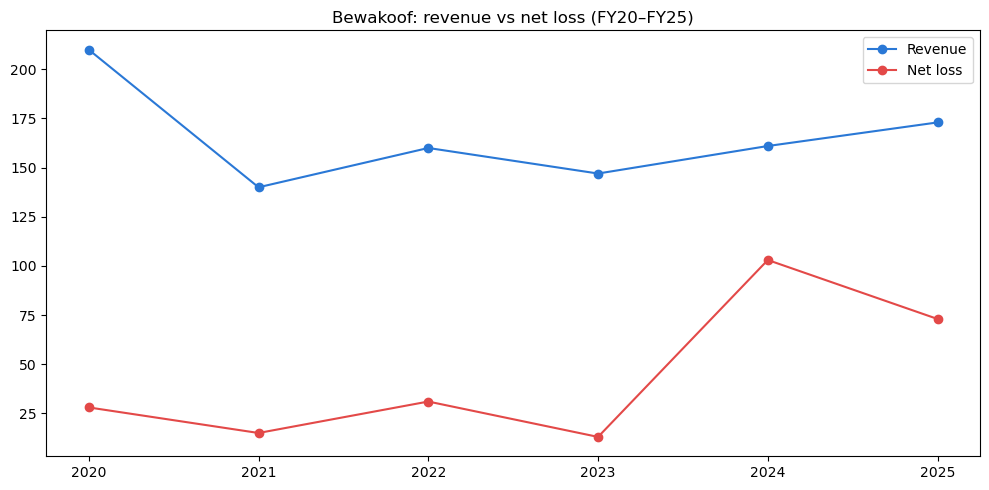

In [ ]:
df['expense_ratio'] = df['expenses'] / df['revenue']

plt.figure(figsize=(10, 5))
plt.plot(df['FY'], df['revenue'],
         label='Revenue', color='#2a78d6', marker='o')
plt.plot(df['FY'], df['net_loss'],
         label='Net loss', color='#e34948', marker='o')
plt.title('Bewakoof: revenue vs net loss (FY20–FY25)')
plt.legend()
plt.tight_layout()
plt.savefig('charts/revenue_trend.png', dpi=150)
plt.show()

## Revenue vs net loss (FY20–FY25)

Revenue peaked at ₹210 Cr in FY20 and has never recovered to that level.
Net loss exploded in FY24 to ₹103 Cr — the worst year on record — driven
by aggressive offline expansion and high employee costs post-acquisition.


In [ ]:
df['expense_ratio'] = (df['expenses'] / df['revenue']).round(2)
df['ebitda'] = df['revenue'] - df['expenses']
df['ebitda_margin'] = ((df['ebitda'] / df['revenue']) * 100).round(1)

print(df[['FY', 'revenue', 'net_loss', 'expense_ratio', 'ebitda_margin']])

     FY  revenue  net_loss  expense_ratio  ebitda_margin
0  2020      210        28           1.13          -13.3
1  2021      140        15           1.11          -10.7
2  2022      160        31           1.19          -19.4
3  2023      147        13           1.65          -64.6
4  2024      161       103           1.65          -64.6
5  2025      173        73           1.43          -43.4


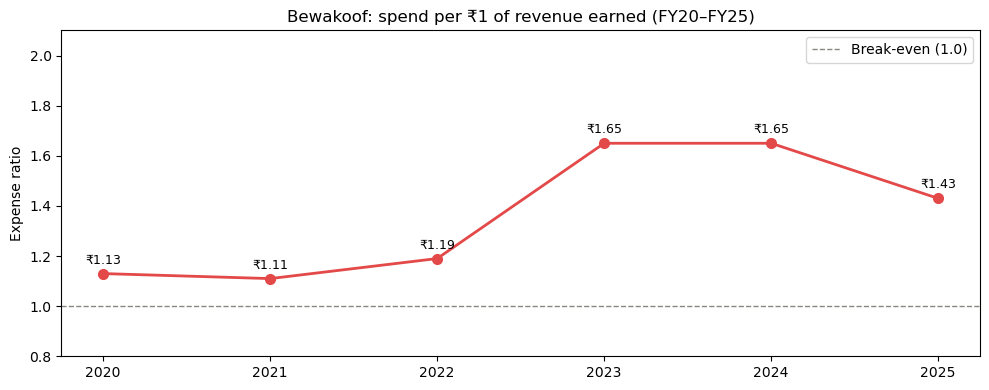

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(df['FY'], df['expense_ratio'],
         color='#e34948', linewidth=2, marker='o', markersize=7)

plt.axhline(1.0, color='#888780', linewidth=1,
            linestyle='--', label='Break-even (1.0)')

for i, row in df.iterrows():
    plt.annotate(f"₹{row['expense_ratio']}",
                 xy=(row['FY'], row['expense_ratio'] + 0.04),
                 ha='center', fontsize=9)

plt.title('Bewakoof: spend per ₹1 of revenue earned (FY20–FY25)')
plt.ylabel('Expense ratio')
plt.ylim(0.8, 2.1)
plt.legend()
plt.tight_layout()
plt.savefig('charts/expense_ratio.png', dpi=150)
plt.show()

## Expense ratio trend

Bewakoof spent ₹1.65 for every ₹1 earned in FY24 — deeply unsustainable.
By FY25 this improved to ₹1.43, showing early signs of cost discipline.
Break-even is 1.0. They are still far from it.


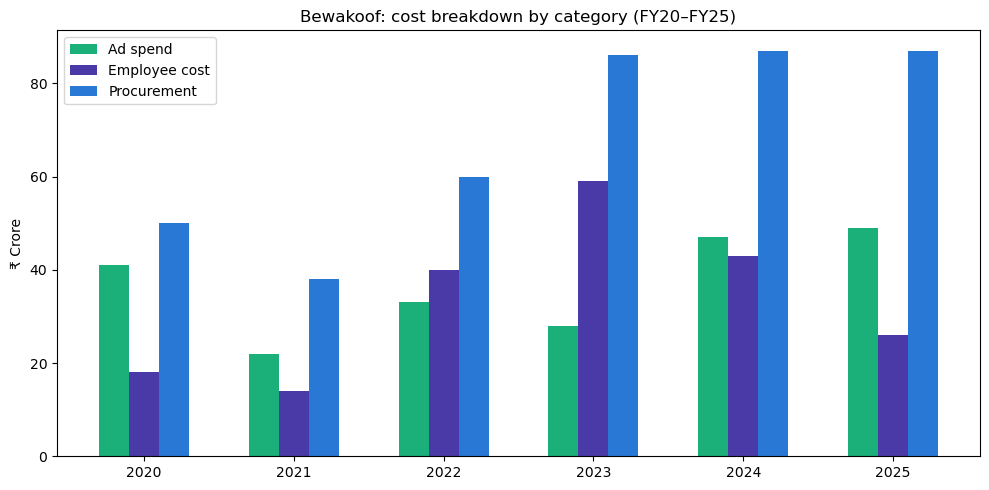

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(df['FY'] - 0.2, df['ad_spend'],
       width=0.2, label='Ad spend', color='#1baf7a')
ax.bar(df['FY'],       df['employee_cost'],
       width=0.2, label='Employee cost', color='#4a3aa7')
ax.bar(df['FY'] + 0.2, df['procurement'],
       width=0.2, label='Procurement', color='#2a78d6')

ax.set_title('Bewakoof: cost breakdown by category (FY20–FY25)')
ax.set_ylabel('₹ Crore')
ax.legend()
plt.tight_layout()
plt.savefig('charts/cost_breakdown.png', dpi=150)
plt.show()

## Cost breakdown by category

Employee costs tripled from ₹18 Cr (FY20) to ₹59 Cr (FY23) after the
Aditya Birla acquisition, then were slashed to ₹26 Cr in FY25 — likely
mass layoffs. Ad spend keeps rising despite stagnant revenue growth.


## Key insight

Bewakoof's expense ratio peaked at ₹1.65 in FY24 — meaning they spent
₹1.65 to earn every ₹1. By FY25 this improved to ₹1.43, but the
business remains structurally loss-making. The core problem is that
ad spend continues rising while revenue growth has stalled.


In [ ]:
competitors = {
    'Brand':    ['Bewakoof', 'Snitch', 'The Bear House', 'Urbanic', 'H&M India'],
    'revenue':  [173,        280,       95,               120,        900],
    'founded':  [2012,       2020,      2012,             2019,       2015],
    'funding':  [115,        0,         0,                30,         0],
    'stores':   [5,          12,        0,                0,          55],
    'type':     ['D2C', 'D2C bootstrapped', 'D2C bootstrapped', 'D2C', 'Retail'],
}

comp = pd.DataFrame(competitors)
print(comp)

            Brand  revenue  founded  funding  stores              type
0        Bewakoof      173     2012      115       5               D2C
1          Snitch      280     2020        0      12  D2C bootstrapped
2  The Bear House       95     2012        0       0  D2C bootstrapped
3         Urbanic      120     2019       30       0               D2C
4       H&M India      900     2015        0      55            Retail


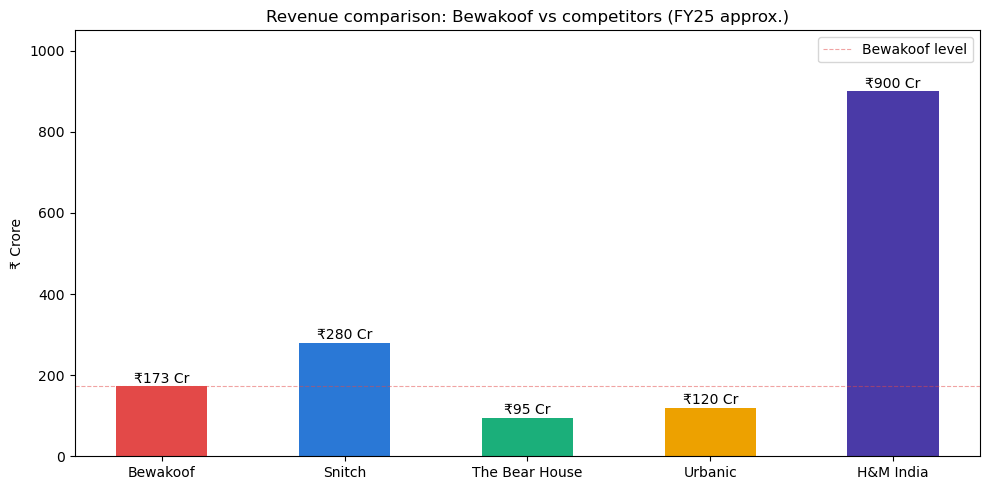

In [ ]:
colors = ['#e34948', '#2a78d6', '#1baf7a', '#eda100', '#4a3aa7']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(comp['Brand'], comp['revenue'],
              color=colors, width=0.5, edgecolor='none')

for bar, val in zip(bars, comp['revenue']):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 8,
            f'₹{val} Cr', ha='center', fontsize=10, fontweight='500')

ax.set_title('Revenue comparison: Bewakoof vs competitors (FY25 approx.)')
ax.set_ylabel('₹ Crore')
ax.set_ylim(0, 1050)
ax.axhline(173, color='#e34948', linewidth=0.8,
           linestyle='--', alpha=0.5, label='Bewakoof level')
ax.legend()
plt.tight_layout()
plt.savefig('charts/competitor_revenue.png', dpi=150)
plt.show()

## Competitor benchmarking

Snitch — founded 8 years after Bewakoof, bootstrapped, zero funding —
already earns ₹280 Cr vs Bewakoof's ₹173 Cr. This is the most damaging
data point in the entire analysis. Bewakoof raised ₹115 Cr in funding
and was acquired for ₹200 Cr, yet a younger bootstrapped competitor
has overtaken it on revenue. This signals a brand positioning failure,
not just a cost problem.


In [5]:
!pip install pytrends

In [10]:
from pytrends.request import TrendReq
import time

pytrends = TrendReq(hl='en-IN', tz=330)

pytrends.build_payload(
    ['bewakoof', 'snitch', 'the bear house'],
    timeframe='2018-01-01 2025-12-31',
    geo='IN'
)

time.sleep(2)
df_trends = pytrends.interest_over_time()
df_trends = df_trends.drop(columns=['isPartial'], errors='ignore')
print(df_trends.tail())

            bewakoof  snitch  the bear house
date                                        
2025-08-01        27      72               6
2025-09-01        24      66               6
2025-10-01        25      78               8
2025-11-01        27      86               8
2025-12-01        25      78               7


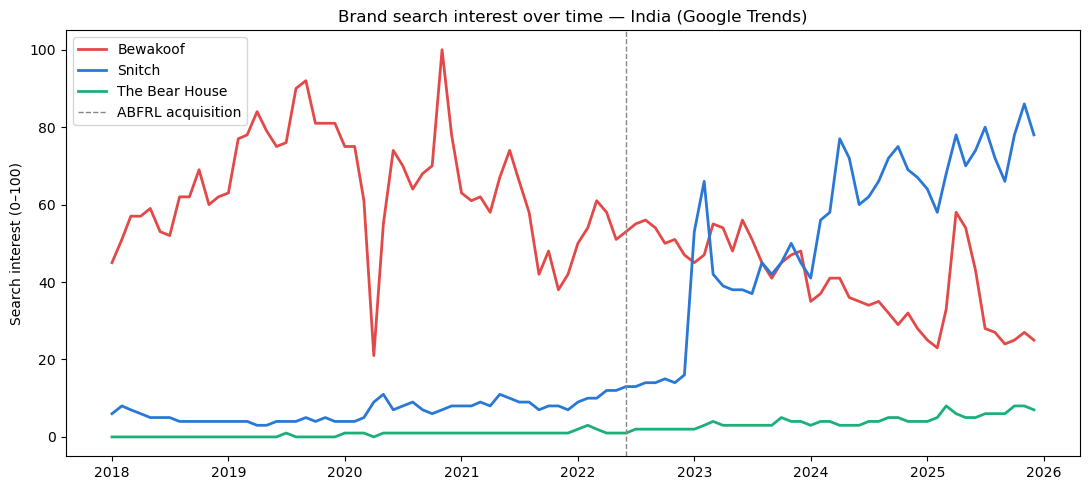

In [12]:
plt.figure(figsize=(11, 5))

plt.plot(df_trends.index, df_trends['bewakoof'],
         label='Bewakoof', color='#e34948', linewidth=2)
plt.plot(df_trends.index, df_trends['snitch'],
         label='Snitch', color='#2a78d6', linewidth=2)
plt.plot(df_trends.index, df_trends['the bear house'],
         label='The Bear House', color='#1baf7a', linewidth=2)

plt.axvline(pd.Timestamp('2022-06-01'), color='#888780',
            linestyle='--', linewidth=1, label='ABFRL acquisition')

plt.title('Brand search interest over time — India (Google Trends)')
plt.ylabel('Search interest (0–100)')
plt.legend()
plt.tight_layout()
plt.savefig('charts/google_trends.png', dpi=150)
plt.show()

## Brand search interest (Google Trends)

Bewakoof's search interest has been declining since 2021 while Snitch
is on a clear upward trajectory. This is brand fatigue made visible —
consumers are actively searching for newer alternatives. The ABFRL
acquisition in 2022 did not reverse this trend.


## Root Cause Analysis

### 1. Brand fatigue

Bewakoof built its identity on one formula — cheap graphic tees with
funny slogans. By 2021 that formula was exhausted. The designs stopped
feeling fresh and younger consumers moved to brands that felt more
curated and premium. Google Trends confirms this — search interest
peaked in 2021 and has fallen every year since.

### 2. Identity loss post-acquisition

The ABFRL acquisition in 2022 was the turning point. Bewakoof went from
a scrappy internet brand to a corporate subsidiary overnight. Physical
stores, expanded product lines, and a ballooning headcount replaced the
lean D2C model that built the brand. Consumers noticed. The brand that
once felt like "us" now felt like every other mall store.

### 3. Rising competition from bootstrapped rivals

Snitch launched in 2020 — 8 years after Bewakoof — with zero funding
and already earns ₹280 Cr vs Bewakoof's ₹173 Cr. The Bear House built
a premium menswear identity with no external capital. These brands proved
that a clear identity beats a big budget every time.

### 4. Cost structure misalignment

Employee costs jumped from ₹18 Cr (FY20) to ₹59 Cr (FY23) — a 3x
increase with no corresponding revenue growth. Ad spend kept rising
even as brand search interest declined, meaning Bewakoof was paying
more to reach fewer interested customers. This is the definition of
an inefficient growth model.

### 5. High return rate

A 30% return rate in FY24 meant ₹69 Cr of gross sales evaporated
before a single cost was counted. For context — that ₹69 Cr alone
is almost equal to the entire net loss of ₹103 Cr that year.
Improving returns to 25% in FY25 saved roughly ₹13 Cr, more than
most cost-cutting measures achieved.


## Recommendations

### 1. Rebuild brand identity

Stop trying to be everything. Pick one lane — either double down on
affordable graphic streetwear for Gen Z, or pivot to premium quality
basics. Half-hearted positioning in both directions is why Snitch
is winning.

### 2. Cut ad spend, invest in community

Bewakoof's early growth came from organic meme marketing and word of
mouth — not paid ads. Ad spend has risen 20% while brand search
interest has fallen. Redirect budget toward UGC campaigns, creator
partnerships, and community building on Instagram and Reddit.

### 3. Fix the return rate further

Each 5% reduction in return rate saves approximately ₹13 Cr in
recovered revenue. Target 20% by FY26 through better size guides,
fabric descriptions, and pre-purchase fit technology.

### 4. Reduce offline footprint

Physical stores added ₹35 Cr in transport and logistics costs in FY25
without proportional revenue gain. Bewakoof was built online — the
offline expansion dilutes the brand and adds cost with limited upside.

### 5. Leverage ABFRL relationships smartly

Instead of becoming a generic retail brand, use ABFRL's supply chain
to reduce procurement costs while keeping the online brand experience
intact. The acquisition should lower costs, not change the identity.
